# Quantum Metal flip-chip tutorial — a crossmon on the qubit chip over a λ/4 on the control chip (Quantcore PDK rebuild)

**What the chip is.** The Qiskit Metal tutorial `docs/tut/2-From-components-to-chip/FlipChip-design-tutorial.ipynb`
(© IBM / Qiskit Metal contributors, Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; spec
`docs/designs/metal/flipchip_qubit_resonator.md`): a `DesignFlipChip` with two facing 9 × 9 mm chips 10 µm apart.
The qubit chip `Q_chip` carries a `TransmonCross` (150 µm arms, 20 µm wide, 20 µm gap, one claw); the control chip
`C_chip` below it a `ReadoutResFC`, a CPW resonator whose open end is a 20 µm-radius disk **directly under the
cross's centre**: the qubit couples to the resonator vertically, across the chip gap. No routes, launchpads or bumps.
The tutorial then runs an HFSS eigenmode + EPR analysis (2 modes, Lj 10 nH). We distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): both
components are drawn through the `metal:<Class>` wrapper with the tutorial's options; the faces, the stack, the
junction, the netlist and the LOM are ours.

| | Qiskit Metal tutorial | Quantcore PDK rebuild |
|---|---|---|
| chips | two 9 × 9 mm chips centred on (0, 0), 10 µm vacuum gap | KQC faces: the control chip is face `1t1` (bottom chip, top face), the qubit chip face `2b1` (top chip, bottom face), on the 7.5 mm Quantcore die |
| frame | none | the QCT frame on face 1t1; face 2b1 has none (PDK v3 defines no frame for the flip-chip top chip; its fab layers are 800–804/0) |
| substrate | custom silicon, εr 11.45 (FEM setting) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| junction | Metal junction line, `hfss_inductance` 10 nH | Quantcore trilayer junction, PDK nominal 0.5 × 0.6 µm (R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF); on face 2b1 its fingers export to 803/0 + 804/0 |
| pads | none | none (nothing for the pad rule to place) |
| cheese | none (the tutorial never exports GDS) | the PDK band (chip `cheese: "auto"`) |
| coupling | geometric, solved by HFSS | declared: the parallel plate between the disk and the cross centre across the 10 µm gap (rough) |
| placement | both chips centred on the pair's origin | the pair's content centred in the die |

**Kept exactly:** both components with the tutorial's options and their relative position (the disk under the
cross centre); Q1 is drawn in the same global (x, y) as R1, on face 2b1 (`face_ids = ["2b1", "1t1", "2t1"]`); both
faces keep their ground plane, as in the source.

**Substituted / added:**
1. The resonator's far end (`readout`) has no route: the trace runs into the ground plane there (Metal draws it so,
   and the tutorial's HFSS model shorts it). The `ReadoutResFC` LOM model makes a free `readout` an open end, so a
   `metal:ShortToGround` (it draws nothing) is snapped onto that pin to make the LOM's line the drawn λ/4.
2. The vertical coupling is not a route: it is declared (`Cg_Q1_R1`) as the parallel plate between the disk and the
   cross centre above it across the 10 µm vacuum gap (1131 µm² overlap → 1.0 fF; rough, fringing ignored).
3. The chip gap (10 µm) and the custom silicon are FEM settings in the source, not layout: the LOM uses the PDK
   substrate. There is no FEM job yet (step 11: the exporter has no two-face stack).

The notebook goes step by step: PDK → die → pads → components → connections → centring → DRC → netlist → LOM →
FEM job → results back → one change re-simulated → fab export → snapshots → summary.

## 1 · Setup

The imports, the output folder and the `LIVE` switch: with KLayout open (the default), every step below is pushed to
the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common`
holds the small helpers the design notebooks share (tables, snapshots, the PDK placement and fab helpers).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement and fab helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
TOP = {"face_ids": ["2b1", "1t1", "2t1"]}        # Q_chip: the top chip's bottom face

## 2 · The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 7.5 mm die gets the QCT frame on the control chip's face 1t1; there are no pads; Q1 gets the PDK nominal trilayer junction (drawn on face 2b1); the free ground of face 1t1 gets the PDK cheese band.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(name, box=...)` opens an empty chip; the box is the die (µm) and the PDK draws the **QCT frame** on it (L
dicing markers 1000/0, 3 × 3 alignment grids 1001/0, chip boundary 100/0, device ID `name_chip` on a free edge). The
source's 9 × 9 mm chips hold only the ≈ 1 mm qubit / resonator pair, so the rebuild uses the 7.5 mm Quantcore die
centred on them (`box=(750, 750, 8250, 8250)`). Metal centres both chips on (0, 0), so a Metal position (x, y) is
`P(x, y)` = (4500 + x, 4500 + y) here, on both faces.

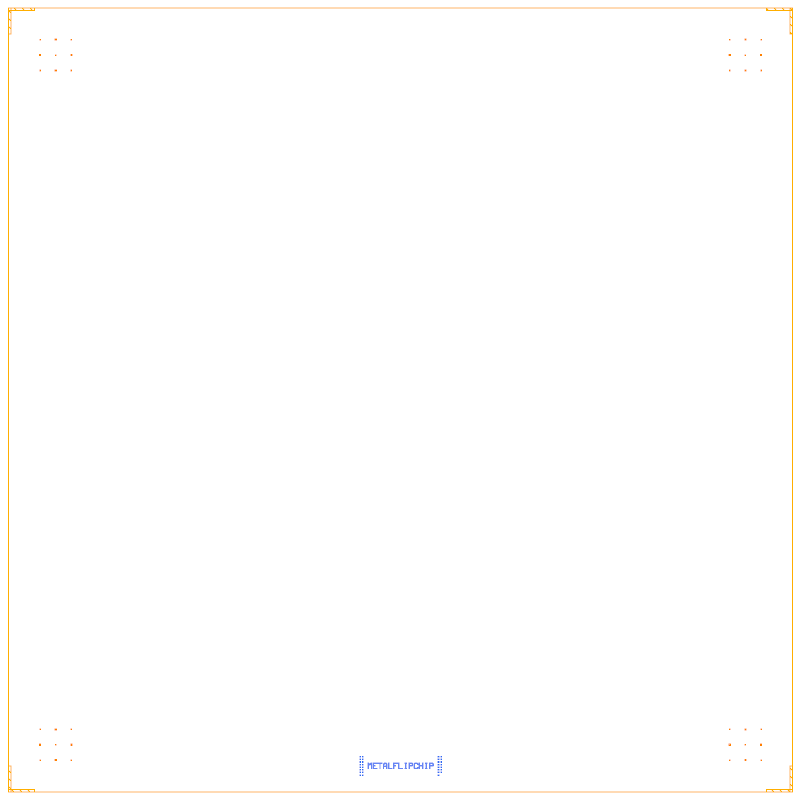

WindowsPath('examples/designs/metal/flipchip_qubit_resonator_step_die.png')

In [4]:
d = Designer("flipchip_qubit_resonator", box=(750, 750, 8250, 8250), chip={"name_chip": "MetalFlipChip"},
             live=LIVE)
P = lambda x, y: (4500 + x, 4500 + y)            # Metal µm → Designer µm (both 9 × 9 mm chips centred on (0, 0))
rebuild(d)
snap(d, OUT / "flipchip_qubit_resonator_step_die.png", size=(800, 800), width=320)

## 4 · Pads

The tutorial has **no launchpads**: the pair is a simulation example, read out in HFSS. So the PDK pad rule (outer
etch of every bond pad 25 µm from the die edge) has nothing to place here; `pads_md` confirms it.

In [5]:
display(Markdown(pads_md(d)))

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

## 5 · Components: the crossmon on the top chip, the resonator on the bottom chip

**The qubit.** `metal:TransmonCross` with the tutorial's options (150 µm arms, 20 µm wide, 20 µm gap) and one claw
`claw_west` (30 µm, the source's `connection_pads`). `TOP` puts it on face **2b1**, the qubit chip's face that looks
down at the control chip: it is drawn in the same global (x, y) as Metal places it. Its junction is the PDK nominal
trilayer junction (`trilayer_junction`: fingers 0.5 × 0.6 µm, R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF); `junction=` carries
L_J and C_J to the LOM. On face 2b1 the fingers export to the face-2b1 junction layers 803/0 + 804/0.

**The claw vs the arm (PDK `pdk_claw`).** A `TransmonCross` claw longer than the arm reach (arm + ground spacing −
half the arm width = 145 µm here) runs into the side arms' gap; the fix is a longer `cross_length`. The 30 µm
claw is far inside it (zoom in step 15).

**The resonator.** `metal:ReadoutResFC` on face 1t1 (the default face): its CPW (10 µm trace, 10 µm gap, 50 µm turn
radius, five sections `readout_l1…l5`) starts at a 20 µm-radius disk under the cross centre.

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


Q1 ports: ['claw_west', 'squid_a', 'squid_b'] | R1 ports: ['readout']


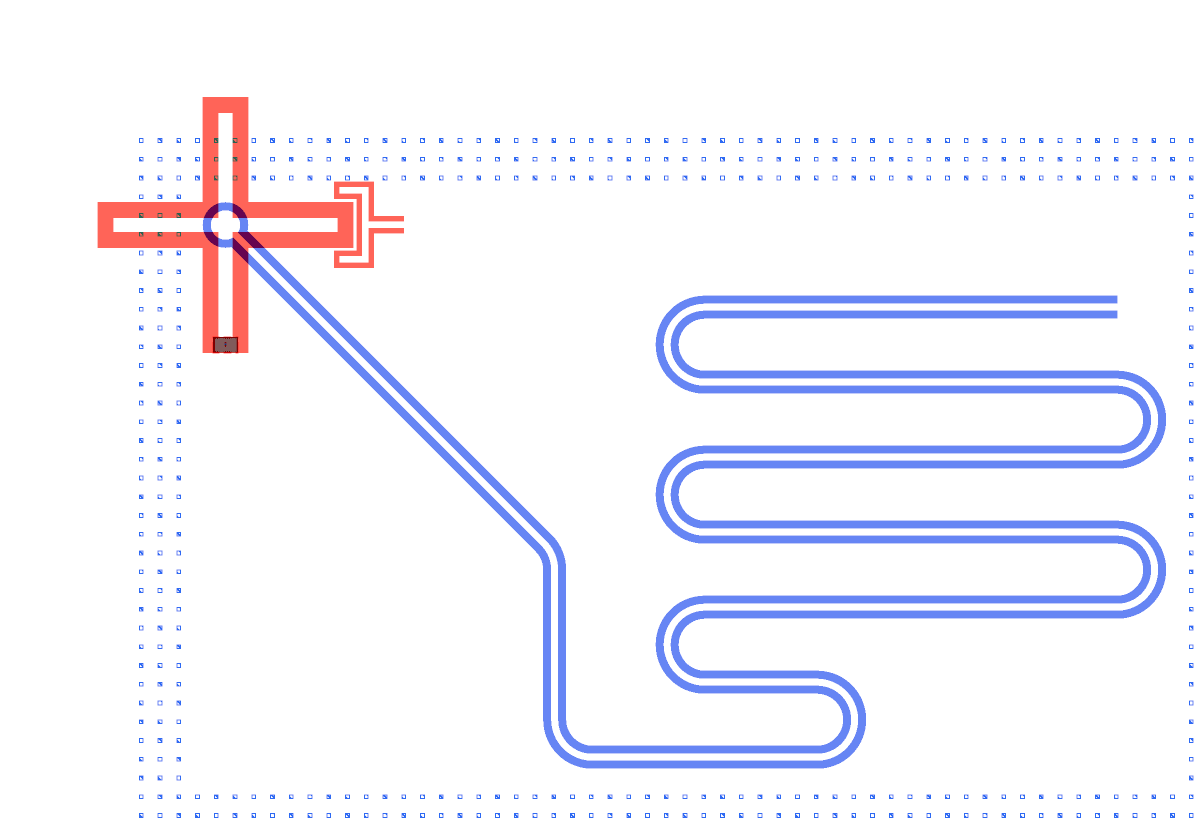

WindowsPath('examples/designs/metal/flipchip_qubit_resonator_step_parts.png')

In [6]:
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
print("junction:", JJ_PARAMS, JUNCTION)
with d.batch():
    claw = dict(connector_type="0", claw_length="30um", ground_spacing="5um", claw_width="10um", claw_gap="6um")
    q1 = d.add("Q1", "metal:TransmonCross", at=P(0, 0), junction=JUNCTION, **JJ_PARAMS, **TOP, cross_width="20um",
               cross_length="150um", cross_gap="20um", connection_pads={"claw_west": {"connector_location": "180", **claw}})
    r1 = d.add("R1", "metal:ReadoutResFC", at=P(0, 0), readout_radius="20 um", readout_cpw_width="10 um",
               readout_cpw_gap="10 um", readout_cpw_turnradius="50 um", readout_l1="600 um", readout_l2="200 um",
               readout_l3="300 um", readout_l4="150 um", readout_l5="550 um", arc_step="5 um")
print("Q1 ports:", sorted(q1.ports), "| R1 ports:", sorted(r1.ports))
snap(d, OUT / "flipchip_qubit_resonator_step_parts.png", box=P(-300, -800) + P(1300, 300), size=(1200, 825), width=480)

## 6 · Connections (no routes)

The source has **no routes**: the qubit and the resonator talk across the chip gap. Two things make the circuit:
- `R1_end`: a `metal:ShortToGround` snapped onto the resonator's `readout` pin (it draws nothing). The drawn trace
  runs into the ground plane there, and the tutorial's HFSS model shorts it: with the short, the LOM's line is the
  drawn λ/4.
- `Cg_Q1_R1`: the vertical coupling, declared with `d.couple`. The disk (r = 20 µm) lies under the cross centre (two
  crossing 20 µm strips), so the overlap is the disk minus the four corner caps beyond |x|, |y| > 10 µm; ε0·A/d
  across the 10 µm vacuum gap gives the capacitance (rough: fringing ignored, which would raise it).

There is no sim group: the FEM exporter builds face 1t1 only (step 11).

overlap 1131 µm² → C_vertical 1.0 fF (parallel plate, rough)


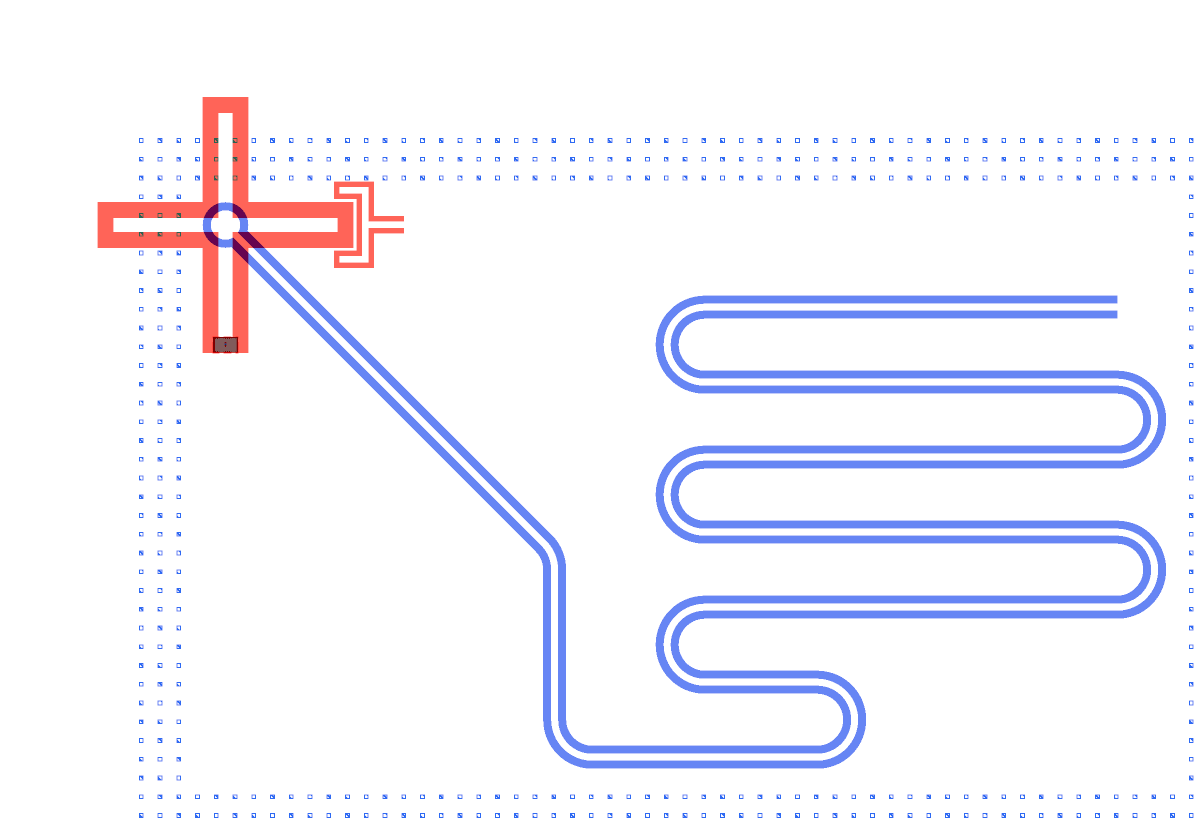

WindowsPath('examples/designs/metal/flipchip_qubit_resonator_step_routes.png')

In [7]:
r, h = 20.0, 10.0                                # disk radius, half the cross strip width (µm)
cap = (lambda F: F(math.sqrt(r * r - h * h)) - F(h))(lambda x: x / 2 * math.sqrt(r * r - x * x) + r * r / 2 * math.asin(x / r)) \
      - h * (math.sqrt(r * r - h * h) - h)
A = math.pi * r * r - 4 * cap                    # disk ∩ cross centre (µm²)
GAP = 10.0                                       # the tutorial's chip gap (µm, vacuum)
C_V = round(8.854e-3 * A / GAP, 2)               # ε0 A / d in fF (ε0 = 8.854e-3 fF/µm)
print(f"overlap {A:.0f} µm² → C_vertical {C_V} fF (parallel plate, rough)")
with d.batch():
    d.add("R1_end", "metal:ShortToGround", snap="short", to="R1.readout")   # the drawn shorted end, for the LOM
    d.couple("Cg_Q1_R1", "Q1", "R1.res", C_fF=C_V, note="disk under the cross centre, 10 µm vacuum gap (rough)")
rebuild(d)
snap(d, OUT / "flipchip_qubit_resonator_step_routes.png", box=P(-300, -800) + P(1300, 300), size=(1200, 825),
     width=480)

## 7 · Centre the content and save

The PDK wants the chip content centred in the die. Metal centres both chips on the qubit, so the pair (the cross and
the resonator that runs 1.2 mm east and 0.7 mm south of it) sits off-centre: `center_in_die` shifts the whole design
(both faces together, the disk stays under the cross) so the content's centre is the die centre. `R1_end` is
snapped and follows R1. Then the design is saved: the JSON is the deliverable.

In [8]:
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
QX, QY = d.data["instances"]["Q1"]["place"]["at"]
P = lambda x, y: (QX + x, QY + y)                # Metal µm → Designer µm after the centring (Q1 is Metal's (0, 0))
DESIGN = d.save(OUT / "flipchip_qubit_resonator.json")
print(d, "→", DESIGN)

content shifted by (-539.4, 274.8) µm
<Designer flipchip_qubit_resonator: 3 instances, 0 routes, live=False> → examples\designs\metal\flipchip_qubit_resonator.json


## 8 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here: **no errors**; three `dangling_port` warnings (Q1's `claw_west`, an open claw on the qubit
chip as in the source, and the junction attachment points `squid_a` / `squid_b`); one `overlap`, Q1 (face 2b1) over
R1 (face 1t1), which is the point of the design: they are on different chips. **No PDK design warnings**: no pads,
the nominal junction is in the R_n window, no target. `pdk_claw` would flag a claw reaching the side arms (it reads
the option strings with their units here, so the check is valid).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [9]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 4 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 3 | Q1.claw_west is not connected (no route or snap) |
| warning | `overlap` | 1 | Q1 and R1 overlap |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, -0) µm |
| junction types | Quantcore Junction × 1 |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: the `TransmonCross` → a grounded cross island with its junction
and C_Σ, a node for the claw; `ReadoutResFC` → its CPW line from the open disk to `readout`, here shorted by `R1_end`
(a λ/4 `TLres`); the declared vertical `Cg_Q1_R1` joins the island and the resonator's open end. The port map shows
which node each port landed on.

In [10]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q1.", "R1"))})

**4 nodes · 6 branches · 0 controls · 1 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `Q1` | `Q1.island` |
| `Q1.claw_west` | `Q1.claw_west` |
| `R1.res` | `R1.res`, `R1_end.end` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_Q1` | C | `Q1` – `gnd` | 64.6 fF |
| `J_Q1` | JJ | `Q1` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_claw_west` | C | `Q1` – `Q1.claw_west` | 1.1 fF |
| `Cc_Q1_claw_west` | C | `Q1.claw_west` – `gnd` | 29.8 fF |
| `C_Cg_Q1_R1` | C | `Q1` – `R1.res` | 1 fF |
| `R1` | TLres | `R1.res` – `gnd` | lambda/4, 4903 µm, 6.415 GHz |

**Unconnected ports:** `Q1.claw_west`

{'Q1.squid_a': 'Q1', 'Q1.squid_b': 'gnd', 'Q1.claw_west': 'Q1.claw_west', 'R1.readout': 'R1.res', 'R1_end.short': 'R1.res'}


## 10 · LOM simulation

QuCat solves the normal modes, QuTiP the dressed values: f_q, α of Q1 and f_r, χ of R1 (κ is 0: the source has no
port). With the PDK junction (6.73 nH, 15 fF) the crossmon sits at ≈ 6.5 GHz, just above the ≈ 6.4 GHz λ/4 (the
tutorial's 10 nH put it at 5.78 GHz), so χ comes out positive (the qubit sits between the resonator and
resonator + |α|); the tutorial reports no values, so there is nothing to compare with except the
PDK band (4–8 GHz). χ comes through the rough 1.0 fF vertical coupling.

In [11]:
res = simulate_groups(d, {"Q1+R1": ["Q1", "R1", "R1_end"]})
display(Markdown(modes_md(res["Q1+R1"]) + "\n\n" + groups_md(res)))

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| R1 | resonator | 6.4036 | 0 | 0.0 | R1 1.00 |
| Q1 | qubit | 6.7880 | 0 | 235.9 | J_Q1 1.00 |

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1+R1 | Q1 | 6.5435 | -269.1 | R1 | 6.4017 | 0 | 11.6 |

## 11 · FEM: send the job (none yet)

The tutorial's analysis is an HFSS eigenmode + EPR of the qubit and the resonator across the 10 µm gap. **qcc cannot
export it yet (open request for sim export):** a sim group of Q1 + R1 exports, but its simulation geometry
is face 1t1 only (`1t1_gap`, `1t1_ground`, one substrate): Q1's metal is on the `2b1_*` layers and never reaches the
solver model, and a C-matrix job finds no nets. The design therefore has **no sim group** until the exporter builds
a two-face stack (KQC `face_stack = ["1t1", "2b1"]` with the chip gap); the vertical coupling stays the LOM's
estimate. The export call below is kept so the notebook exports the group once it exists.

`RUN_FEM = False` keeps the notebook fast. Set it to `True` to solve the jobs here: `send_fem_jobs` finds AEDT 2024
R1 (or newer) and solves each Ansys job in a **new batch, non-graphical** AEDT, so an AEDT window you have open is
never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [12]:
jobs = export_sims(DESIGN)                       # every sim group of the design: none yet
print(len(jobs), "FEM jobs")

0 FEM jobs


In [13]:
RUN_FEM = False   # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
if RUN_FEM:
    send_fem_jobs(DESIGN, None, run=True)

## 12 · Bring the FEM results back

When a job has been solved, its folder holds `results/results.json`, and `fem_back` fills the LOM with the extracted
C-matrix (matched by net name) and lists each capacitance as estimate vs extracted. This design has no job yet, so
the cell has nothing to bring back: the declared `Cg_Q1_R1` and the cell estimates stay the LOM values.

In [14]:
filled, back_md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(back_md or "No FEM job for this design yet (no two-face export): nothing to bring back."))
for key, fc in filled.items():                   # re-simulate the LOM on the extracted values
    display(Markdown(f"**{key}, LOM on the FEM values:**"))
    display(Markdown(modes_md(simulate(fc))))

No FEM job for this design yet (no two-face export): nothing to bring back.

## 13 · Iterate: change one property and re-simulate

Copy the saved design (`design_copy`: a non-live Designer that never writes over the JSON), change one property —
here the resonator's first section `readout_l1`, 600 → 500 µm, 100 µm off the λ/4 — rebuild, re-run the LOM and
compare. A shorter λ/4 resonates higher (f ∝ 1/ℓ, ≈ +2 %); the qubit barely moves; χ grows as the resonator moves
towards the qubit.

In [15]:
d2 = design_copy(DESIGN)
d2["R1"].set(readout_l1="500 um")                # 600 → 500 µm
res2 = simulate_groups(d2, {"Q1+R1": ["Q1", "R1", "R1_end"]})
display(Markdown(params_delta_md(res, res2)))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1+R1: R1.f_GHz` | 6.4017 | 6.5183 | +0.1166 |
| `Q1+R1: R1.kappa_MHz` | 0 | 0 | +0 |
| `Q1+R1: R1.chi_MHz` | 11.572 | 29.711 | +18.14 |
| `Q1+R1: Q1.f_q_GHz` | 6.5435 | 6.56 | +0.01653 |
| `Q1+R1: Q1.alpha_MHz` | -269.08 | -301.84 | -32.76 |

## 14 · Build and export

The design JSON saved in step 7 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** The flip-chip tutorial never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer of face 1t1 (5 µm squares, 20 µm
gaps, three rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`). The qubit's face 2b1
exports to 800–804/0 (no frame and no cheese band there).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [16]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

design file: examples\designs\metal\flipchip_qubit_resonator.json


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 559 |
| 3/0 | M3 | 551 |
| 50/0 | HSQ | 2 |
| 51/0 | SPACER_1 | 2 |
| 52/0 | SPACER_2 | 2 |
| 53/0 | SPACER_3 | 2 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 800/0 | FC_M1 | 2 |
| 803/0 | FC_JJ_1 | 1 |
| 804/0 | FC_JJ_2 | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 545 holes on the mask.

→ `build/flipchip_qubit_resonator_fab.oas`

## 15 · Snapshots

Both faces (red: the qubit chip's face 2b1, blue: the control chip's face 1t1; compare the tutorial's screenshot);
the cross centre over the resonator's disk (and the 30 µm claw, well inside the arm reach); the resonator's shorted
end; the **fab mask** round the pair (face-1t1 etch with the PDK cheese band, the 3/0 keep-out; face 2b1 on
800–804/0); and the die frame's south-west corner (dicing L on 1000/0, alignment grid on 1001/0). Positions are read
from the design after the centring shift (`P` is relative to Q1).

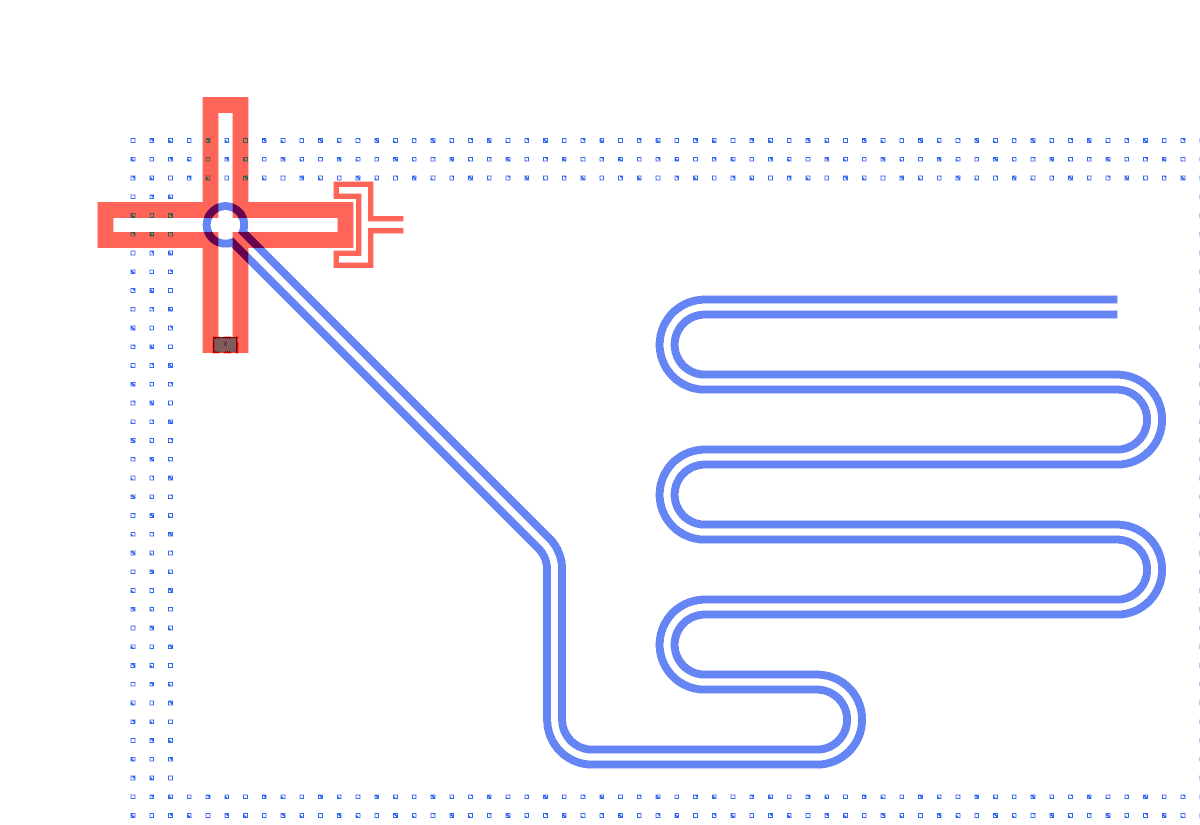

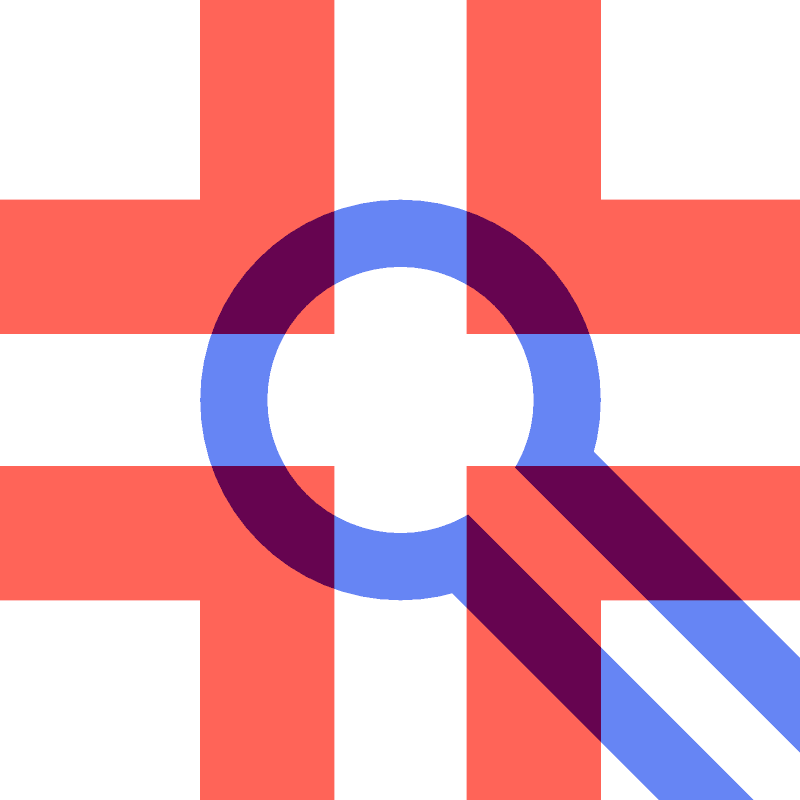

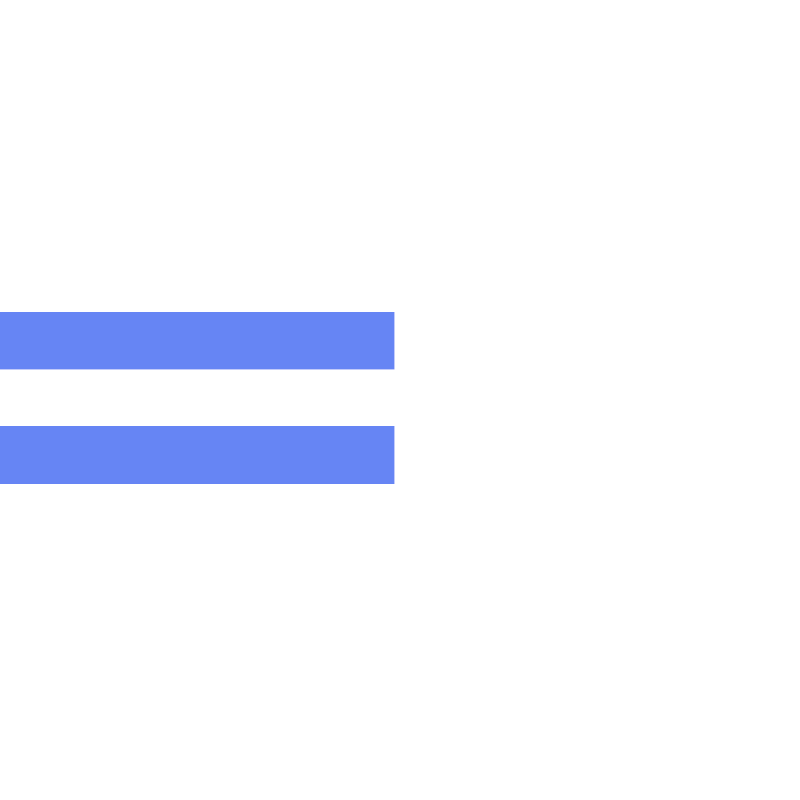

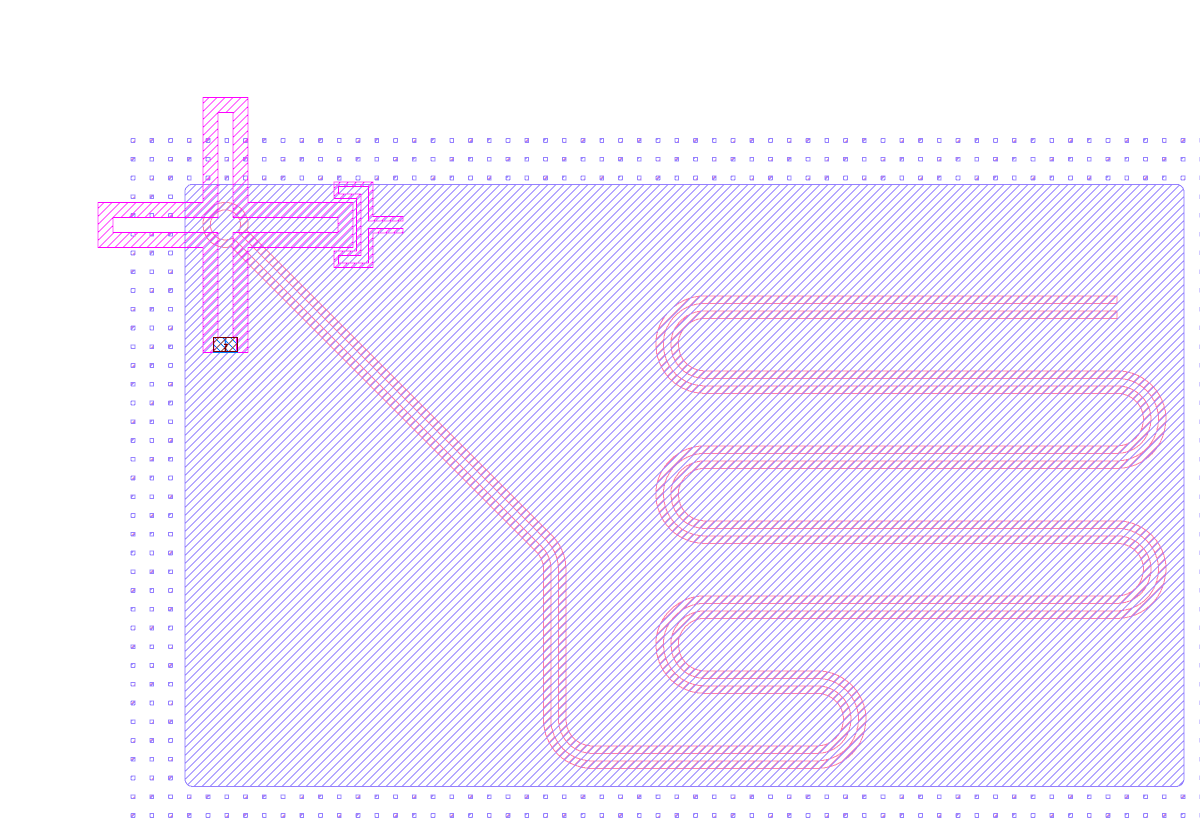

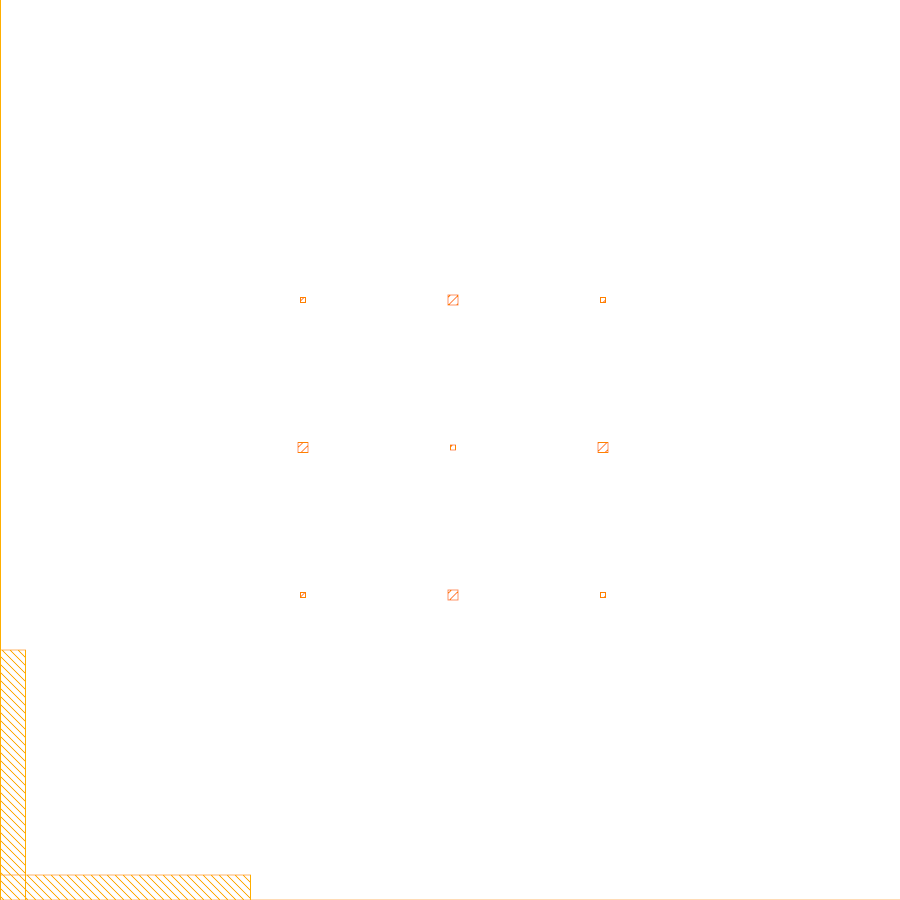

In [17]:
show_snapshot(d, OUT / "flipchip_qubit_resonator.png", box=P(-300, -800) + P(1300, 300), size=(1200, 825))
show_snapshot(d, OUT / "flipchip_qubit_resonator_disk.png", box=P(-60, -60) + P(60, 60), size=(800, 800), width=320)
show_snapshot(d, OUT / "flipchip_qubit_resonator_end.png", box=P(1120, -180) + P(1260, -40), size=(800, 800), width=320)
snap_file(Path("build") / "flipchip_qubit_resonator_fab.oas", OUT / "flipchip_qubit_resonator_cheese.png",
          box=P(-300, -800) + P(1300, 300), size=(1200, 825), width=480)
show_snapshot(d, OUT / "flipchip_qubit_resonator_frame.png", box=(750, 750, 1650, 1650), size=(900, 900), width=300);

## 16 · Summary

| | |
|---|---|
| matches the source | both Metal components and their options, the disk under the cross centre, the two faces (qubit chip over control chip), the shorted resonator end |
| PDK changes | the 7.5 mm die with the QCT frame on face 1t1; sapphire stack; trilayer junction (PDK nominal, on face 2b1 → 803/0 + 804/0); PDK cheese band on face 1t1; content centred (shift (−539, +275) µm) |
| differs | the vertical coupling is a declared parallel-plate estimate (1.0 fF); f_q 6.54 GHz with the PDK junction (the tutorial's 10 nH gave 5.78 GHz), just above the 6.40 GHz λ/4, so χ is positive (+11.6 MHz, straddling) |
| PDK design warnings | none |
| open | no FEM job: the exporter has no two-face (flip-chip) stack yet; no PDK frame for the top chip (face 2b1) |